# Simulation des Isingmodells in Python

Dieses Dokument soll euch dabei unterstützen, eine Simulation des Ising-Modells zu programmieren. Dazu ist es in mehrere Teilaufgaben unterteilt:
- Zunächst werden wir mit einer fixen Spinkonfiguration arbeiten ("Spinkonfiguration" bezeichnet hier eine Konstellation von magnetischen Einheiten mit einer von zwei möglichen Ausrichtungen: +1 oder -1. Man könnte statt "Spin" auch "Elementarmagnet" sagen). Wir werden lernen, wie man eine Spinkonfiguration erzeugt und wie man sie anzeigt. Wir werden relevante physikalisch Parameter einer Spinkonfiguration (nämlich Magnetisierung und Energie) berechnen. Und wir werden lernen, wie man eine gegebene Spinkonfiguration modifiziert.
- Anschließend werden wir mit Hilfe des Metropolis-Hastings-Algorithmus das Verhalten einer Spinkonfiguration bei thermischen Fluktuationen simulieren.
- Schließlich werden wir die die Simulation dazu verwenden, physikalische Größen zu ermitteln ("zu messen"), um etwas über die Physik von Ferromagneten zu lernen.

Wenn ihr euch erfolgreich durch dieses Dokument gearbeitet habt und eure Simulation des Ising-Modells zum Laufen gebracht habt, dann könnt ihr eurem Forscherdrang weiter nachgehen, indem ihr eine von vielen spannenden Erweiterungen und Modifikationen des Modells vornehmt oder eure eigenen Ideen umsetzt.

## Arbeiten mit einer fixen Spinkonfiguration

Für unsere Simulation werden wir zwei Python-Bibliotheken benötigen:
- Numpy, für numerische Berechnungen und Arrays (Listen)
- Matplotlib, für schöne Bilder und Visualisierungen

Diese Bibliotheken müsste ihr zu Beginn einmal importieren, damit ihr auf die Befehle daraus zurückgreifen könnt. Dazu müsst ihr nur die folgende Zelle ausführen:

In [1]:
import numpy as np
from matplotlib import pyplot as plt

Zunächst arbeiten wir mit einer gegebenen Spinkonfiguration. Diese wird durch ein zweidimensionales Numpy-Array dargestellt. Jeder Eintrag dieses Arrays ist entweder 1 oder -1. Dies entspricht den beiden Ausrichtungen, die ein Spin in unserem Modell annehmen kann. Durch Ausführen der folgenden Zelle wird eine solche feste Spinkonfiguration unter dem Namen "sk" gespeichert.

In [2]:
#  Definition einer festen Spinkonfiguration

sk= np.array([
       [-1, -1, -1, -1, -1, -1, -1, -1, -1, -1],
       [-1, -1, -1, -1,  1, -1, -1,  1, -1, -1],
       [-1,  1, -1,  1,  1,  1,  1, -1,  1, -1],
       [-1,  1,  1,  1,  1, -1,  1, -1,  1, -1],
       [-1, -1,  1,  1,  1, -1,  1, -1,  1, -1],
       [-1,  1,  1,  1,  1,  1, -1,  1,  1, -1],
       [-1, -1,  1,  1, -1, -1,  1,  1,  1, -1],
       [-1,  1,  1,  1, -1, -1,  1, -1, -1, -1],
       [-1, -1, -1,  1,  1,  1,  1,  1, -1, -1],
       [-1, -1, -1, -1, -1, -1, -1, -1, -1, -1]])

Zunächst einige nützliche Befehle:

Das Gitter mit der gegebenen Spinkonfiguration lässt sich mit folgenden Befehlen anzeigen: ``plt.imshow()`` (als Argument den anzuzeigenden Array) und danach ``plt.show()`` (mit leerem Argument).

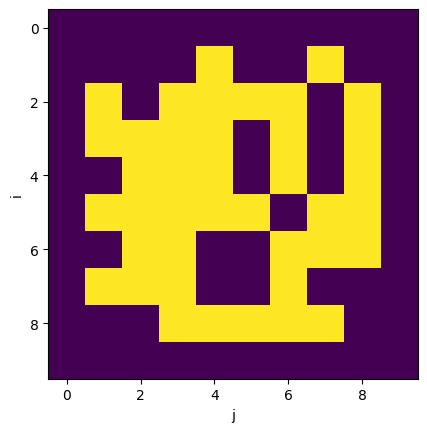

In [3]:
plt.imshow(sk)
plt.xlabel("j")
plt.ylabel("i")
plt.show()

Die Position auf dem Gitter wird durch 2 Koordinaten angegeben. Mit folgendem code könnt ihr den Wert des Spins an der Position $(i,j)$ abrufen: ``sk[i,j]``

In [4]:
sk[0,4]

-1

Wenn die größe des Gitters erfahren wollt hilft der Befehl ``np.shape()``, dieser gibt ein Array mit den Seitenlängen aus.

In [5]:
np.shape(sk)

(10, 10)

### Aufgabe 1 (Magnetisierung)


Die Magnetisierung $m$ ist die gemittelte Ausrichtung aller $N$ Spins:
$$ m=\sum_{s} s /N \;.$$

$s$ ist dabei der Wert des jeweiligen Spins (also +1 oder -1).

*Schreibt eine Funktion ``mag()``, die die Magnetisierung einer gegeben Spinkonfiguration berechnet, und testet sie, indem ihr die Magnetisierung auch per Hand berechnet.*

*Zur Kontrolle: Für die zu Beginn gegebene Spinkonfiguration gilt ``mag(sk)=-0.2``*

In [6]:
def mag_auf(inp):
    m = 0
    dim = np.shape(inp)
    for i in range(dim[0]):
        for j in range(dim[1]):
            m += inp[i][j]
            print(i)
    m = m / (dim[0] * dim[1])
    return m

def mag(f):
    return np.average(f)

In [7]:
mag(sk)

-0.2

### Aufgabe 2 (Energie)

Die Energie einer Spinkonfiguration $S$ wird wie folgt berechnet: für jeden Spin $s_{(x,y)}$, an der Stelle $(x,y)$, schauen wir uns dessen nächste Nachbarn an und erhalten den Energiewert $-1$, wenn der Nachbarspin gleich ausgerichtet ist, bzw. $+1$ im entgegengesetzten Fall. Für die Gesamtenergie summiert man alle diese Werte für jeden Spin auf. Als Formel ausgedrückt:
$$ E(S) = - \frac{1}{2} \sum_{x = 0}^{L}\sum_{y = 0}^{L} \ \sum_{(\tilde x,\tilde y) \sim (x, y)} s_{(x,y)} s_{(\tilde x,\tilde y)} \;.$$
Hierbei bedeutet $(\tilde x,\tilde y) \sim (x, y)$, dass $(\tilde x,\tilde y)$ ein benachbarter Gitterpunkt zu $(x,y)$ ist. Also ist $s_{(\tilde x,\tilde y)}$ ein Nachbarspin von $s_{(x,y)}$.

*a) Versteht ihr, wie die Formel die im Text beschriebene Energieberechnung darstellt? Warum gibt es einen Faktor von ein Halb?*
weil jede Verbindung doppelt gewertet wird


*b) Schreibt eine Funktion ``energie()``, die die Energie einer gegeben Spinkonfiguration berechnet.*

*Hinweis: Falls es beim Ausführen der Funktion zu einer Fehlermeldung kommt, lest unten weiter.*

In [8]:
def energie(f, r = "p"):
    e = 0
    dim = np.shape(f)
    if(r == "p"):
        for i in range(dim[0]):
            for j in range(dim[1]):
                e += f[i,j] * f[(i-1) % dim[0],j]
                e += f[i,j] * f[(i+1) % dim[0],j]
                e += f[i,j] * f[i             ,(j-1) % dim[1]]
                e += f[i,j] * f[i             ,(j+1) % dim[1]]
    if(r == "0"):
        for i in range(dim[0]):
            for j in range(dim[1]):
                try:
                   e += f[i,j] * f[i-1,j] 
                except:
                    pass
                try:
                   e += f[i,j] * f[i+1,j] 
                except:
                    pass
                try:
                   e += f[i,j] * f[i,j-1] 
                except:
                    pass
                try:
                   e += f[i,j] * f[i,j+1] 
                except:
                    pass
    if(r == "1"):
        for i in range(dim[0]):
            for j in range(dim[1]):
                try:
                    e += f[i,j] * f[i-1,j] 
                except:
                    e+= f[i,j]
                try:
                   e += f[i,j] * f[i+1,j] 
                except:
                    e+= f[i,j]
                try:
                   e += f[i,j] * f[i,j-1] 
                except:
                    e+= f[i,j]
                try:
                   e += f[i,j] * f[i,j+1] 
                except:
                    e+= f[i,j]
    if(r == "-1"):
        for i in range(dim[0]):
            for j in range(dim[1]):
                try:
                    e += f[i,j] * f[i-1,j] 
                except:
                    e-= f[i,j]
                try:
                   e += f[i,j] * f[i+1,j] 
                except:
                    e-= f[i,j]
                try:
                   e += f[i,j] * f[i,j-1] 
                except:
                    e-= f[i,j]
                try:
                   e += f[i,j] * f[i,j+1] 
                except:
                    e-= f[i,j]
    if(r == "rand"):
        for i in range(dim[0]):
            for j in range(dim[1]):
                try:
                    e += f[i,j] * f[i-1,j] 
                except:
                    e+= f[i,j] * np.random.choice([-1,-1])
                try:
                   e += f[i,j] * f[i+1,j] 
                except:
                    e+= f[i,j] * np.random.choice([-1,-1])
                try:
                   e += f[i,j] * f[i,j-1] 
                except:
                    e+= f[i,j] * np.random.choice([-1,-1])
                try:
                   e += f[i,j] * f[i,j+1] 
                except:
                    e+= f[i,j] * np.random.choice([-1,-1])

    e = -0.5 * e
    return e



In [9]:
energie(sk, "0")

-54.0

Es kann sein, dass ihr folgenden Fehler bekommt:
```
IndexError: index 10 is out of bounds for axis 1 with size 10
```

*c) Was ist das Problem?*

Man kann die Spins am Rand des Gitters gesondert betrachten, oder sog. **periodische Randbedingungen** einführen. Das heißt: die jeweils gegenüberliegenden Ränder werden "zusammengeklebt"; die rechten Nachbarn der Spins am rechten Rand sind also die Spins am linken Rand.

Um periodische Randbedingungen zu implementieren, hilft die Operation "modulo" (quasi Division mit Rest) ``%``.

In [10]:
print( 0%10, 1%10, 2%10, 10%10, 11%10)

0 1 2 0 1



*d) Warum sind periodische Randbedingungen im Modell sinnvoll?*


*e) Verwendet Modulo-Operationen, um die Energie mit periodischen Randbedingungen zu berechnen.*

### Aufgabe 3 (Spinflip)

Später brauchen wir für den Metropolis-Hastings Algorithmus eine Funktion, die einen bestimmten Spin umkehrt.

*a) Schreibt eine solche Funktion ``spinflip()``, die als Inputs eine gegeben Spinkonfiguration und die Position des zu flippenden Spins nimmt, und eine neue Spinkonfiguration, mit geflipptem Spin, ausgibt.*

*Wichtiger Hinweis: Nutzt ``np.copy()`` um eine Kopie des urspünglichen Arrays zu erstellen. Ansonsten kann es passieren, dass ihr auch das Original verändert.*

In [11]:
def spinflip(f, x, y):
    f[x,y] *= -1
    return f

Wenn ihr die folgende Zelle ausführt, seht ihr eine Visualisierung eurer Funktion: Links die originale Spinkonfiguration und rechts die Konfiguration, bei der der Spin an der Stelle (4,3) mit dem Befehl ``spinflip(sk,4,3)`` umgekehrt wurde.

Macht eure Funktion das, was sie soll?

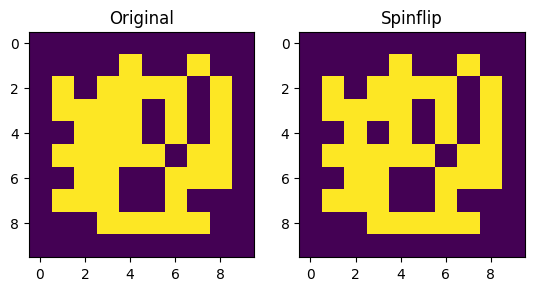

In [12]:
plt.figure()
plt.subplot(121)
plt.title("Original")
plt.imshow(sk)
plt.subplot(122)
plt.title("Spinflip")
plt.imshow(spinflip(sk,4,3))
plt.show()

Später wird uns vor allem interessieren wie groß die Energieänderung ist, wenn ein Spin an der Stelle $(i,j)$ geflippt wird.

*b) Schreibt eine Funktion ``delta()``, die diesen Energieunterschied berechnet. Wie könnt ihr geschickt per Hand nachprüfen, ob eure Funktion korrekt funktioniert?*

In [13]:
def delta(f, x, y, r = "p"):
    d = 0
    dim = np.shape(sk)
    if(r == "p"):
        d += f[x,y] * f[(x-1) % dim[0],y]
        d += f[x,y] * f[(x+1) % dim[0],y]
        d += f[x,y] * f[x             ,(y-1) % dim[1]]
        d += f[x,y] * f[x             ,(y+1) % dim[1]]
    d *= 2
    return d

In [14]:
delta(sk, 4, 3)

-8

Damit die Simulation später nicht zu langsam wird, ist es wichtig, effiziente Algorithmen zu implementieren, sodass der Computer nicht viele unnötige Berechnungen durchführen muss. Die Funktion ``energie()`` benötigt vergleichsweise viele Rechenschritte, da über alle Spins summiert werden muss. Deshalb wollen wir versuchen, die Verwendung dieser Funktion zu vermeiden, wenn es auch effizientere Methoden zur Berechnung gibt.

Um den Energieunterschied bei einem Spinflip zu berechnen, kann man ``energie()`` verwenden, aber es ist nicht notwendig.

*c) Wie kann man den Energieunterschied nach einem Spinflip schlauer berechnen, ohne mit  ``energie()`` die Gesamternergie vor und nach dem Flip zu berechnen? Hinweis: Beachtet, dass jeder Spin nur mit seinen direkten Nachbarn wechselwirkt. Es kann helfen wenn ihr euch ein paar Beispiele von Spinkonfigurationen aufmalt.
Macht euch Gedanken darüber, bevor ihr weiterlest.*

Hier die Lösung der Frage:


(Ihr könnt auch durch Zeichnen und Nachdenken auf die Lösung kommen. Hier wird die Lösung mit Formeln präsentiert.)

Die Energie wird berechnet, indem nacheinander alle Gitterpunkte unabhänging voneinander betrachtet werden.
$$ \Delta (S\to S') = E(S')-E(S) = - \frac{1}{2} \sum_{x=0}^{L} \sum_{y=0}^{L} \sum_{(\tilde x,\tilde y) \sim (x, y)} \left( s'_{(x,y)}  s'_{(\tilde x,\tilde y)} - s_{(x,y)}  s_{(\tilde x,\tilde y)} \right) \;. $$
Darum gibt es nur einen Energieunterschied wenn sich die Spins an der Position $(x,y)$ in den beiden Konfigurationen $S$ und $S'$ unterscheiden. Da in unserem Fall $S'$ durch das flippen des Spins an der Stelle $(i,j)$ aus $S$ erzeugt wird müssen wir auch nur die Energie der Spins an dieser Stelle vergleichen. Dabei ist ein Faktor $2$ zu beachten, denn jede "Verbindung" zwischen einem Spin und seinem Nachbar wid doppelt gezählt - jeder Spin ist Nachbar seines Nachbarn.
$$ \Delta (S\to S') = - \frac{1}{2}*2 \sum_{(\tilde x,\tilde y) \sim (i, j)} \left(s'_{(i,j)}  s'_{(\tilde x,\tilde y)} - s_{(i,j)}  s_{(\tilde x,\tilde y)} \right) \;. $$
Durch den Spinflip gilt außerdem $s'_{(i,j)} = - s_{(i,j)}$ und $s'_{(x,y)}=s_{(x,y)}$ an allen anderen Postitionen $(x,y)\neq (i,j)$.
$$ \Delta (S\to S') = 2 \sum_{(\tilde x,\tilde y) \sim (i, j)} s_{(i,j)}  s_{(\tilde x,\tilde y)}  \;. $$

*d) Schreibt eine effiziente Methode ``delta()``, die den Energieunterschied berechnet, ohne ``energie()`` zu benutzen.*

## Metropolis-Hastings Algorithmus

Jetzt sind wir endlich bereit, das dynamische Verhalten des Spingitters unter thermischen Fluktuationen zu simulieren - und dazu werden wir den Metropolis-Hasting-Algorithmus verwenden! Das Ziel des Algorithmus ist es, typische Spinkonfigurationen für die gegebene Temperatur zu generieren, an denen wir später Messungen (wie in einem Zufallsexperiment) ausführen können.

Zur Erinnerung, in den Vorträgen zur „Monte-Carlo-Methode“ haben wir das Spiel mit dem Werfen von Steinen innerhalb eines großen Quadrats gespielt:
1. Beginne in einer Ecke
2. Wirf einen Stein in eine zufällige Richtung
3. Bewege dich zu seiner Position, wenn der Stein nicht außerhalb des Quadrats gelandet ist; andernfalls bringe den Stein zurück in die Ausgangsposition
4. Wiederhole die Schritte 2. bis 3.

Nach einer ausreichenden Anzahl von Würfen hast du das gesamte Quadrat zufällig umrundet (random walk) - die auf diese Weise gebildete Kette von Stichproben (Positionen) wird Markov-Kette genannt.

Ein Metropolis-Hastings-Algorithmus baut ebenfalls eine Markov-Kette von Stichproben auf, aber ein Sprung zu einer neuen Konfiguration erfolgt mit einer gewissen Wahrscheinlichkeit. Um Stichproben zu erzeugen, die den physikalischen und statistischen Gesetzen entsprechen, muss diese Sprung-Wahrscheinlichkeit in einer bestimmten Weise von der Energie und der Temperatur des Systems abhängen.

Die Wahrscheinlichkeit einer Spinkonfiguration $S$ ist gegeben durch die Boltzmann-Verteilung:
$$ P(S) = \frac{ e^{-\beta E(S)}}{Z} \;, \quad Z = \sum_{S} e^{-\beta E(S)} .$$

wobei $ \beta = T^{-1} $ die inverse Temperatur und $ E(S) $ die Energie für eine bestimmte Spinkonfiguration $S$ ist.

Jetzt, da wir wissen, dass unsere Sprung-Wahrscheinlichkeit die Form des Boltzmann-Faktors $\exp(-\beta \Delta E)$ haben muss, können wir unseren Algorithmus definieren:

1.   starte mit zufälliger Konfiguration
2.   flippe einen zufälligen Spin
3.   berechne den Energieunterschied ΔE zw. neuer und alter Konfiguration
  *   falls  $ΔE \leq 0$  akzeptiere die neue Konfiguration
  *   falls  $ΔE > 0$  akzeptiere die neue Konfiguration nur mit einer Wahrscheinlichkeit von $\exp(-\beta \Delta E)$
4.    wiederhole die Schritte 2. bis 3.


### Anfangskonfiguration



Wir wollen mit einer zufälligen Anfangskonfiguration von Spins beginnen. Erzeugt also ein Array, welches zufällig mit 1 oder -1 gefüllt wird.

*Hinweis: Die Funktion `` np.random.choice()`` kann helfen. Das erste Argument dieser Funktion ist eine Liste aus deren einträgen zufällig gewählt werden soll. Das zweite Argument bestimmt die Größe des zu erzeugenden Arrays - z.B. (27,27) erzeugt ein 2d Array mit 27x27 Einträgen.*

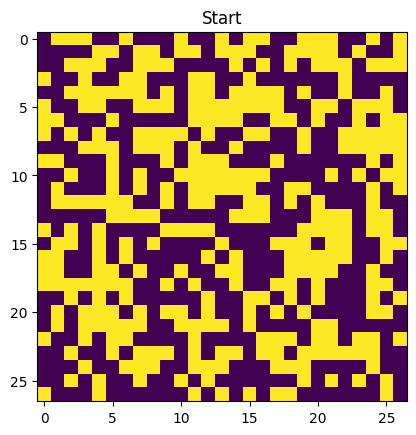

In [15]:
beta = .1   # inverse Temperatur
l = 27    # Seitenlänge des Gitters
start = np.random.choice([-1, 1], size=(l,l))

plt.imshow(start)
plt.title("Start")
plt.show()

### Schritt und Sprung







In einem Schritt des Algorithmus soll Folgendes passieren:

1.   Wählt eine neue Konfiguration $S\to S'$. Am einfachsten ist es einen zufälligen Spin zu flippen.
2.   Berechnet die Energiedifferenz $\Delta (S\to S')$.
3.   Wenn $\exp(-\beta \Delta(S\to S'))> \text{zufällige Zahl zw. 0 und 1}$ ist, dann wird die neue Konfiguration $S'$ akzeptiert, und falls nicht wird die alte Konfiguration $S$ beibehalten.

Der 3. Punkt bedeutet, dass die neue Konfiguration mit einer Wahrscheinlichkeit von $\min(\exp(-\beta \Delta),1)$ akzeptiert wird.

*a) Was passiert in einem Schritt, wenn die neue Konfiguration energetisch günstiger/ungünstiger/gleich ist?*

Im folgenden nennen wir $N$ Schritte einen Sprung, wobei $N$ gleich der Anzahl der vorhandenen Spins in der Spinkonfiguration ist. Typischerweise sollte man etwa 20 Sprünge durchführen, bevor man Datenn sammelt oder Messungen durchführt, um sicherzustellen, dass der Algorithmus ausreichend oft angewendet wurde (d.h. um sicherzustellen, dass wir viele mögliche Spinkonfigurationen generiert haben, und nicht nur die Konfigurationen, die der ursprünglichen nahe kommen).

*b) Implementiert so einen Sprung in Python.*

*Hinweise: Mit ``np.random.randint(k)`` erhaltet ihr eine zufällge Ganze Zahl aus $\{0, 1, 2, \dots, k-1\}$ und mit ``np.random.rand()`` eine zufällige rationale Zahl zwischen 0 und 1. Die Exponentialfunktion könnt ihr mit ``np.exp()`` abrufen.*

In [16]:
def sprung(f, times, b, s = []):
    dim = np.shape(f)
    n = np.size(f)

    for i in range(times):
        for k in range(n): # n Schritte in Sprung
            f = schritt(f, n, dim, b)

        if (i+1 in s):
            plt.imshow(f)
            plt.title("Sprung " + str(i+1))
            plt.show()

    return f

def schritt(f, n, dim, b):

    x = np.random.randint(dim[0])
    y = np.random.randint(dim[1])

    if (np.exp(-b * delta(f, x, y)) > np.random.rand()):
        f = spinflip(f, x, y)
    return f

*c) Lasst euch die Konfiguration nach einem Sprung und nach vielen (z.B. 20) Sprüngen anzeigen. Was könnt ihr feststellen? Macht mehrere Versuche und verändert dabei die Zahl der Sprünge und den Parameter $\beta$. Wie beeinflusst dies das Ergebnis? Entspricht dies dem, was ihr erwarten würdet?*

In [18]:
beta = 0.01
l = 27
start = np.random.choice([-1, 1], size=(l,l))

sprung(start, 2, beta)


array([[ 1, -1,  1,  1,  1,  1, -1, -1, -1,  1,  1,  1,  1,  1,  1,  1,
        -1, -1,  1,  1, -1,  1,  1,  1,  1,  1,  1],
       [ 1,  1,  1, -1, -1, -1,  1,  1,  1,  1, -1, -1, -1, -1,  1,  1,
         1,  1, -1, -1,  1,  1, -1, -1,  1, -1, -1],
       [ 1, -1,  1,  1, -1, -1, -1,  1, -1,  1, -1,  1, -1,  1, -1, -1,
         1, -1, -1,  1,  1, -1, -1, -1, -1, -1, -1],
       [ 1,  1,  1,  1, -1, -1,  1, -1, -1,  1, -1,  1,  1,  1,  1, -1,
         1,  1, -1, -1,  1,  1,  1, -1,  1,  1, -1],
       [ 1,  1,  1, -1, -1,  1, -1,  1, -1, -1, -1, -1, -1, -1,  1, -1,
         1,  1, -1,  1, -1,  1,  1, -1, -1, -1, -1],
       [ 1,  1, -1, -1,  1, -1, -1,  1, -1, -1,  1, -1,  1,  1, -1,  1,
         1, -1, -1, -1,  1,  1,  1,  1, -1,  1,  1],
       [ 1, -1, -1, -1, -1,  1, -1,  1,  1, -1,  1, -1,  1, -1, -1,  1,
        -1, -1, -1,  1,  1, -1, -1, -1,  1, -1, -1],
       [ 1, -1,  1, -1, -1,  1,  1, -1,  1, -1,  1, -1,  1,  1,  1,  1,
        -1,  1,  1, -1, -1, -1,  1, -1,  1,  1, -1],


## Messungen


Nun sind wir bereit, unsere Simulation zu nutzen, um endlich Physik zu machen!

### Feste Temperatur

Zunächst wollen wir untersuchen, wie sich unser Isingmodell bei einer festen Temperatur verhält. Wir interessieren uns dabei für die durchschnittliche Magnetisierung und Energie des Spingitters.

Zunächst ein Wort zum Kerngedanken der Statistischen Physik:
Unsere Simulation beruht auf der Verwendung von Zufallszahlen. Bei der Simulation eines Ferromagneten (oder allgemeiner: eines beliebigen komplexen Systems) ist dies sinnvoll, um den Umstand zu berücksichtigen, dass das betrachtete System zu kompliziert ist, um alle mikroskopischen Prozesse detailliert zu beschreiben. Dies impliziert aber auf der anderen Seite, dass das Ergebnis eines einzelnen Prozesses auch einen zufälligen Ausgang nimmt. Um trotzdem interessante Erkenntnisse über das untersuchte System zu gewinnen, müssen wir uns also der Statistik bedienen. Dies bedeutet: Wir müssen viele Messungen machen, um statistische Größen wie Mittelwerte etc. zu berechnen. Ist die Anzahl der Messungen nicht groß genug, so sind die Erkenntnisse, die wir daraus gewinnen können, nicht statistisch signifikant. Dazu später mehr.

Ziel dieser Aufgabe ist es also, viele Messungen von Magnetisierung und Energie des Spingitters zu machen. Die thermischen Fluktuationen, die die interne Dynamik  im Ferromagneten bescheiben, werden durch die Sprünge simuliert. Zunächst wollen wir eine ausreichend große Menge von Messungen durchführen, diese anschließend graphisch darstellen und schließlich statistische Methoden anwenden, um Erkenntnisse über das Verhalten des Spingitters zu gewinnen.

*a) Wählt eine Temperatur (bzw. ein $\beta$), z.B. $0,1$. Macht eine ausreichend große Zahl von Messungen der Energie und der Magnetisierung des Spingitters (z.B. 50). Dabei ist es wichtig, dass zwischen jeder Messung ausreichend viele Sprünge simuliert werden, damit zwei Messungen nicht miteinandern korreliert sind (20 Sprünge zwischen jeder Messung ist ein guter Wert). Speichert die Messergebnisse in einer Liste E für die Energie und einer weiteren Liste M für die Magnetisierung.*

In [20]:
beta = 0.01
l = 10
sf = np.random.choice([-1, 1], size=(l,l))
e = []
m = []

for i in range(150):
    sf = sprung(sf, 20, beta)
    e.append(energie(sf))
    m.append(np.average(sf))


Wir wollen nun unsere Messergebnisse in einem Diagramm (auch "Plot" genannt) darstellen. Dazu verwenden wir die Bibliothek Matplotlib, die wir ganz am Anfang importiert haben. Um die Daten in einem Array graphisch darzustellen, könnt ihr den Befehl ``plt.plot()`` verwenden. Dieser Befehl kann ein oder zwei Argumente nehmen. Das erste Argument ist der Array, den ihr plotten wollt. Das zweite, optionale Argument bestimmt das Design, mit dem die Datenpunkte dargestellt werden sollen. Probiert z.B. einmal das Design 'or'.

*b) Plottet die Messergebnisse der Energie und der Magnetisierung. Vermutlich ist es besser, zwei getrennte Plots für Energie und Magnetisierung zu machen, indem ihr die entsprechenden Befehle in getrennte Zellen schreibt.*

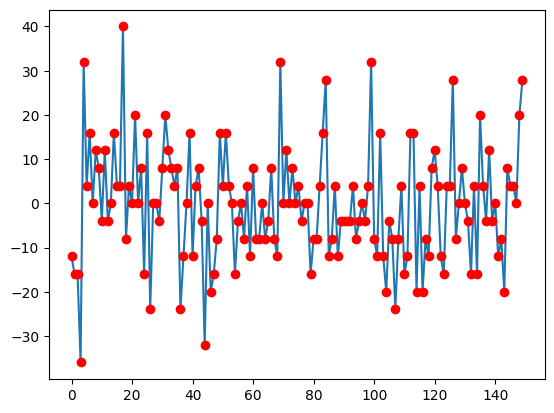

In [21]:
plt.plot(e)
plt.plot(e, 'or')

In [24]:
beta = 0.8
l = 27
sf_2 = np.random.choice([-1, 1], size=(l,l))
e_2 = []
m_2 = []

for i in range(50):
    sf_2 = sprung(sf_2, 1, beta)
    e_2.append(energie(sf_2))
    m_2.append(np.average(sf_2))


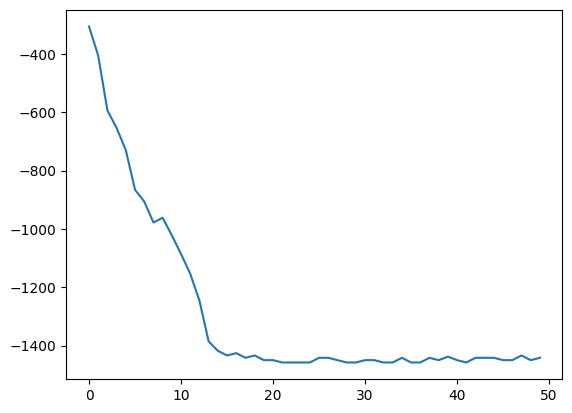

In [25]:
plt.plot(e_2)

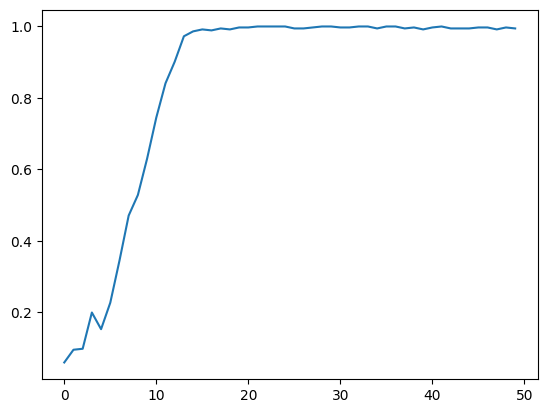

In [26]:
plt.plot(m_2)

*c) Schaut euch eure Plots an. Was könnt ihr erkennen? Wie würden die Messergebnisse aussehen, wenn aufeinander folgende Messungen statistisch korreliert wären, also die Zahl der Sprünge dazwischen zu gering wäre? Ist dies der Fall? Wenn ihr wollt, könnt ihr eure Vermutungen überprüfen, indem ihr die Messungen mit einer anderen Anzahl von Sprüngen wiederholt.*


Nun haben wir eine gewisse Menge an Daten über unser System gesammelt. Jede einzelne Messung ist dabei von den Zufällen im Algorithmus geprägt. Aber zusammen liefern die Messungen interessante Informationen über das System. Dabei sind insbesondere zwei statistische Kenngrößen von großer Bedeutung:
1. Der Mittelwert einer Variable
2. Die Standardabweichung einer Variable

Die Standardabweichung ist ein Maß für die Streuung, der eine gewisse Größe unterliegt. Je größer die Standardabweichung, desto zufälliger ist jedes einzelne Ereignis. Hat eine Größe eine kleine Standardabweichung, liegen also nahezu alle Ereignisse nahe beim Mittelwert. Ist die Standardabweichung hingegen sehr groß, so ist jedes Ereignis quasi zufällig und kann stark vom Mittelwert abweichen. In diesem Fall ist der Mittelwert nicht sehr aussagekräftig.

Es gibt Formeln für die Berechnung von Mittelwert und Standardabweichung einer Größe aus einer Reihe von Messdaten dieser Größe. Zum Glück gibt es in der Bibliothek Numpy aber Befehle, die diese Berechnungen für uns übernehmen. Daher müssen wir uns nicht mit den mathematischen Details der Standardabweichung herumschlagen. Mit ``np.mean()`` könnt ihr ganz einfach den Mittelwert der Werte eines Arrays berechnen, mit ``np.std()`` erhaltet ihr die Standardabweichung.

*d) Berechnet den Mittelwert und die Standardabweichung der gemessenen Energie und Magnetisierung.*

In [27]:
print(np.mean(e))
print(np.std(e))

print(np.mean(m))
print(np.std(m))

-0.26666666666666666
12.913386680323468
0.0044
0.0992470318615793


Schaut euch die Ergebnisse an. Vermutlich ist die Standardabweichung der Magnetisierung deutlich größer als der Mittelwert.

*e) Was bedeutet das? Könnt ihr erklären, woran es liegt?*

Wir können mehr Informationen über die Magentisierung erhalten, indem wir nicht die Magnetisierung selbst, sondern den Absolutbetrag $|M|$ betrachten. Dieser ist definiert als der Wert, den man erhält, wenn man das Vorzeichen weglässt. Also z.B. |2|=2, aber |-5|=5.
Der Befehl ``np.abs()`` berechnet den Absolutbetrag einer Zahl oder eines Arrays.

*f) Berechnet den Mittelwert und die Standardabweichung von $|M|$ und vergleicht mit den vorherigen Ergebnissen für $M$. Was sagt dies über die Magnetisierung aus? Warum ist die Information über $|M|$ interessanter als die von $M$? Und warum müssen wir bei der Energie nicht den Absolutbetrag nehmen?*

In [28]:
m_abs = []
for i in m:
    m_abs.append(np.abs(i))

print(np.mean(m_abs))
print(np.std(m_abs))

0.07693333333333333
0.06285376325690893


### Verschiedene Temperaturen

Der letzte Schritt ist nun, zu untersuchen, welchen Einfluss die Temperatur auf das Ising-Modell hat. Wählt dazu eine Anzahl an Temperaturen (bzw. $\beta$-Parameter) aus und führt für jeden davon eine Simulation wie oben durch. Überlegt euch, wie viele Sprünge und Messungen ihr pro Temperatur machen wollt, damit ihr auf der einen Seite genug Messungen für eine statistische Analyse habt, aber die Ausführung des Programms auf der anderen Seite nicht allzu lange dauert.

*a) Bestimmt für jede der gewählten Temperaturen wie oben die mittlere Magnetisierung (bzw. deren Absolutbetrag) und die mittlere Energie sowie die entsprechenden Standardabweichungen. Speichert die Ergenisse in Arrays.*

In [30]:
# Mögliche Parameter (Vorschlag):
n_spruenge = 100
messung = 40
betas = [0.1,0.2,0.25,0.3,0.33,0.35,0.37,0.4,0.42,0.43,0.44,0.45,0.46,0.47,0.5,0.53,0.57,0.6,0.65,0.7,0.8]
l = 27

# Euer code
e_mean = []
e_std = []
m_mean = []
m_std = []

for b in betas:
    e_iteration = []
    m_iteration = []
    sf = np.random.choice([-1, 1], size=(l,l))
    
    for i in range(messung):
        sf = sprung(sf, int(n_spruenge/messung), b)
        e_iteration.append(energie(sf))
        m_iteration.append(np.abs(np.mean(sf))) #np.mean ist Magnetisierung
    
    e_mean.append(np.mean(e_iteration))
    e_std.append(np.std(e_iteration))

    m_mean.append(np.mean(m_iteration))
    m_std.append(np.std(m_iteration))


Wir wollen die Messergebnisse wieder graphisch darstellen. Diesmal in einem Diagramm, das die verwendeten Temperaturen bzw. $\beta$-Parameter auf der x-Achse und die Mittelwerte der zugehörigen Messgröße ($E$ bzw. $|M|$) auf der y-Achse plottet. Außerdem wollen wir die Standardabweichungen der Messwerte im selben Diagramm graphisch darstellen, um auf einen Blick erkennen zu können, wie groß die Streuung der einzelnen Werte ist. Dazu verwenden wir ein Diagramm mit sogenannten "Fehlerbalken". Dies sind Striche durch einen Datenpunkt, die genau eine Standardabweichung nach oben und unten reichen. Somit kann die Standardabweichung eines Wertes direkt aus dem Diagramm abgelesen werden, und gleichzeitig erhält man eine graphische Intuition für die Genauigkeit eines Wertes.

Um ein solches Diagramm zu erstellen, könnt ihr den Befehl ``plt.errorbar()`` benutzen. Dieser nimmt drei oder vier Argumente, nämlich:
1. Einen Array mit den Werten für die x-Achse
2. Einen Array mit den Werten für die y-Achse
3. Einen Array mit den Standardabweichungen der Werte für die y-Achse
4. Optional: Das Design des Plottes (fmt='or' ist eine gute Möglichkeit)

*b) Erstellt Plots eurer Messergebnisse mit Fehlerbalken.*

<ErrorbarContainer object of 3 artists>

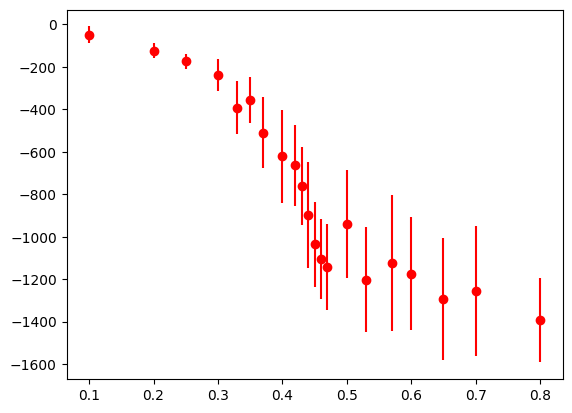

In [31]:
# plt.plot(m_mean)
plt.errorbar(betas, e_mean, e_std, fmt='or')

plt.plot()

<ErrorbarContainer object of 3 artists>

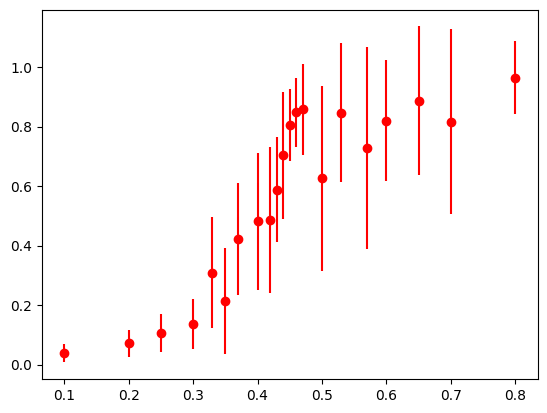

In [32]:
plt.errorbar(betas, m_mean, m_std, fmt = 'or')

*c) Schaut euch die Plots an. Was erkennt ihr? Wie verhält sich das Spin-Gitter für kleine und für große Temperaturen? Könnt ihr dieses Verhalten physikalisch erklären? Was passiert dazwischen? Wie nennt man ein derartiges Verhalten in einem solchen Diagramm?*

*d) Übertragt eure Erkenntnisse auf reale Magneten. Was würde passieren, wenn ihr einen Ferromagneten stark abkühlen oder erhitzen würdet?*

Schließlich wollen wir den Phasenübergang noch etwas genauer untersuchen. Dazu betrachten wir eine weitere physikalische Größe: die Wärmekapazität $C$. Diese beschreibt, wie stark sich Energie eines Systems ändert, wenn die Temperatur erhöht wird. Mathematisch ausgedrückt ist die Wärmekapazität die Ableitung der Energie nach der Temperatur:

$$ C=\frac{\partial E}{\partial T} $$

(Diese Notation der Ableitung wird in der Schule in der Regel nicht verwendet, ist aber in der Physik sehr gebräuchlich).

Es gibt eine andere Möglichkeit, die Wärmekapazität zu berechnen, und zwar mit der Standardabweichung der Energie $\sigma$:

$$ C=\frac{\sigma^2}{T^2} = \sigma^2 \beta^2 $$

Eine charakteristische Eigenschaft von Phasenübergängen ist, dass gewisse Systemgrößen am Phasenübergang ein unstetiges Verhalten aufweisen, also zum Beispiel divergieren. Eine solche Systemgröße ist in unserem Fall die  Wärmekapazität. Wenn man diese als Funktion der Temperatur (oder von $\beta$) graphisch aufträgt, so verhält sie sich stetig bis zu einer kritischen Temperatur $T_c$. Bei $T_c$ divergiert $C$, geht also gegen unendlich.

*e) Berechnet die Wärmekapazität $C$ für alle Temperaturen, bei denen ihr Messpunkte genommen habt. Plottet dann die Wärmekapazität als Funktion der Temperatur (bzw. des $\beta$-Parameters). Könnt ihr das beschriebene Verhalten feststellen? Ermittelt die kritische Temperatur $T_c$.*

In [33]:
c = []

for i in range(len(betas)):
    c.append(e_std[i]**2 * betas[i]**2)

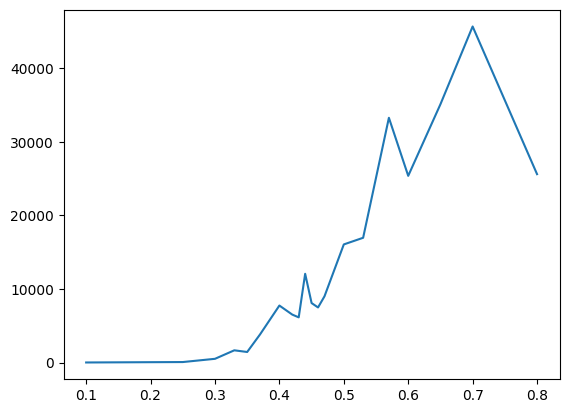

In [34]:
plt.plot(betas, c)


Glückwunsch! Ihr habt alle Aufgaben geschafft und das Ising-Modell erfolgreich in Python simuliert! Gute Arbeit!

Wenn ihr wollt, könnt ihr euch nun weiter mit Python austoben und weitere Erkenntnisse über Ferromagneten gewinnen, indem ihr eure Simulation modifiziert. Ihr könnt gerne eigene Ideen umsetzen, wenn ihr wollt. Alternativ haben wir ein paar Vorschläge für euch, was interessante Modifikationen und Erweiterungen sein könnten. Am Sonntag könnt ihr das, was ihr gemacht habt, den anderen Gruppen präsentieren. Probiert euch aus und habt Spaß mit eurem Ising-Modell!